In [1]:
%load_ext autoreload
%autoreload 2
from mg_sampling import PROJECT_DIR
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from ast import literal_eval
import itertools
from functools import reduce
from mg_sampling.tools import bayesian_bootstrap, read_plumed

### Motifs

In [2]:
def atom_latex_name(s):
    return f"\mathrm{{{s[0]}}}_\mathrm{{{s[1:]}}}"

def motif_latex_name(x):
    names = x['inner_names']
    resnames = x['inner_resnames']
    resids = x['inner_resids']
    mgrna = x['mgrna']
    motif = ",".join(f"${atom_latex_name(name)}^\mathrm{{{resname}{resid}}}$" for resname, resid, name in zip(resnames, resids, names))
    if x['stereo']:
        motif = x['stereo'] + "-" + motif
    return motif

def motif_name(x):
    names = x['inner_names']
    resnames = x['inner_resnames']
    resids = x['inner_resids']
    mgrna = x['mgrna']
    motif = ",".join(f"{resname}{resid}{name}" for resname, resid, name in zip(resnames, resids, names))
    if mgrna:
        motif += '-' + mgrna
    return motif

def label_disjoint_sets(sets):
    """
    From a list of sets, find group membership such that
    non-disjoint sets belong to the same group.
    """
    from scipy.cluster.hierarchy import DisjointSet
    # Groupping by non-empty intersection
    # In: a list of sets {a, b, c}, {d, e}, {e, f}, {a}, {g, h}...
    # Out: a list of group id such as sets with non-null intersection belong to the same group
    #      0, 1, 1, 0, 2 ...
    # Algo: list elements a, b, c, d, e, f, g, ...
    #       assign different group ids
    #       for each pair of sets, if s1 & s2 != 0, set all elements of s1 | s2 to the leftmost id

    ds = DisjointSet()
    for s in sets:
        for x in s:
            ds.add(x)
            ds.merge(x, s[0])
    
    group_ids = [ds._parents[s[0]] for s in sets]
    _, group_ids = np.unique(group_ids, return_inverse=True)

    return group_ids

In [3]:
def summarize_motifs(df):
    df['motif'] = df.apply(motif_name, axis=1).astype('category')

    # Create a unique id for each block of data for error estimate
    df['block'], _ = pd.factorize(df[['replicate', 'repid']].apply(tuple, axis='columns'))

    count = df.groupby(['block', 'time', 'motif'], observed=True).size()
    count = count.unstack('motif', fill_value=0)

    p_block = count.groupby('block').mean()
    block_weight = count.groupby('block').size().rename('block_weight')
    block_weight /= block_weight.sum()

    p = p_block.mul(block_weight, axis='index').sum().rename('p')

    # Error estimate: bayesian bootstrap with blocks
    ci = p_block.apply(
        lambda x: tuple(map(float, bayesian_bootstrap(x, np.average, weights=block_weight).confidence_interval))
    ).transpose().set_axis(['p_low', 'p_high'], axis='columns')

    n_block_obs = (p_block > 0).sum().rename('n_block_obs')

    res = pd.concat([p, ci, n_block_obs], axis='columns')

    res = res.join(
        df.drop_duplicates(subset='motif', keep='first').set_index('motif')[['n_inner', 'inner_indices', 'inner_names', 'inner_resids', 'inner_resnames', 'stereo', 'mgrna']]
    )

    mg_indices = df.groupby('motif', observed=True)['index'].agg(lambda x: list(set(x))).rename('mg_indices')
    res = res.join(mg_indices)

    return res


In [28]:
# Replex
t_start = 50000  # ps
t_end = 200000 # ps
systems = ['7ez0', '7ez0_noion']
replicates = [0, 1]
repids = range(8)

for sys in systems:
    df = pd.DataFrame()
    for rep, i in itertools.product(replicates, repids):
        _df = pd.read_parquet(PROJECT_DIR / f'replex/{sys}/mMg_tip3p/replicate{rep}/rep{i+8*rep:02d}/MG_motifs.parquet').assign(replicate=rep, repid=i)
        colvar = read_plumed(PROJECT_DIR / f'replex/{sys}/mMg_tip3p/replicate{rep}/rep{i+8*rep:02d}/bias.COLVAR.{i}')
        colvar['time'] = colvar['time'].astype(int)
        _df['reptemp'] = colvar.set_index('time').loc[_df['time'].astype(int), 'bias.index'].astype(int).values
        _df = _df.query('time >= @t_start and time < @t_end')
        df = pd.concat([df, _df])

    # Multiplexing and analysis
    for λ in repids:
        res = summarize_motifs(df.query('reptemp == @λ').copy())
        res.to_parquet(PROJECT_DIR / f'replex/{sys}/mMg_tip3p/MG_motifs_summary_lambda{λ}.parquet')

In [29]:
res

,p,p_low,p_high,n_block_obs,n_inner,inner_indices,inner_names,inner_resids,inner_resnames,stereo,mgrna,mg_indices
motif,,,,,,,,,,,,
,113.366667,112.536572,114.317223,16,0,[],[],[],[],,,"[269531, 269532, 269533, 269534, 269535, 26953..."
A103O1P-Oph,0.227667,0.141778,0.326521,15,1,[2606],[O1P],[103],[A],,Oph,"[269572, 269704, 269705, 269577, 269580, 26958..."
A103O2P-Oph,0.031333,0.003174,0.087964,2,1,[2607],[O2P],[103],[A],,Oph,"[269677, 269574]"
A104O1P-Oph,0.057667,0.011031,0.148391,6,1,[2639],[O1P],[104],[A],,Oph,"[269543, 269708, 269647, 269683, 269564, 269663]"
A104O2P-Oph,0.182000,0.087481,0.292715,10,1,[2640],[O2P],[104],[A],,Oph,"[269634, 269646, 269615, 269614, 269649, 26961..."
...,...,...,...,...,...,...,...,...,...,...,...,...
U84O2P-Oph,0.027333,0.008753,0.058039,9,1,[1996],[O2P],[84],[U],,Oph,"[269568, 269706, 269582, 269584, 269553, 26968..."
U85O1P-Oph,0.043000,0.008269,0.088870,5,1,[2025],[O1P],[85],[U],,Oph,"[269698, 269699, 269700, 269576, 269547, 26955..."
U85O2P-Oph,0.010000,0.002459,0.021188,3,1,[2026],[O2P],[85],[U],,Oph,"[269625, 269708, 269558]"


In [30]:
# Plain MD
t_start = 150000  # ps
t_end = 500000 # ps
systems = ['7ez0', '7ez0_noion']
forcefields = ['mMg_tip3p', 'nMg_tip3p', 'nMg_tip3p_soft']
replicates = range(8)

for sys, ff in itertools.product(systems, forcefields):
    df = pd.DataFrame()
    for rep in replicates:
        try:
            _df = pd.read_parquet(PROJECT_DIR / f'plain_md/{sys}/{ff}/rep{rep:02d}/MG_motifs.parquet').assign(replicate=rep, repid=0)
        except FileNotFoundError as e:
            break
        _df = _df.query('time >= @t_start and time < @t_end')
        df = pd.concat([df, _df])
    else:
        res = summarize_motifs(df)
        res.to_parquet(PROJECT_DIR / f'plain_md/{sys}/{ff}/MG_motifs_summary.parquet')

res

,p,p_low,p_high,n_block_obs,n_inner,inner_indices,inner_names,inner_resids,inner_resnames,stereo,mgrna,mg_indices
motif,,,,,,,,,,,,
,144.001429,1.420540e+02,146.237706,8,0,[],[],[],[],,,"[269531, 269532, 269533, 269534, 269535, 26953..."
"A103HO'2,A104O2P-cis-OphX",0.000036,7.907388e-07,0.000113,1,2,"[2636, 2640]","[HO'2, O2P]","[103, 104]","[A, A]",cis,cis-OphX,[269626]
A103O1P-Oph,0.052821,6.484376e-03,0.137835,3,1,[2606],[O1P],[103],[A],,Oph,"[269660, 269654, 269687]"
A103O2P-Oph,0.130071,1.134743e-02,0.345956,2,1,[2607],[O2P],[103],[A],,Oph,"[269602, 269694]"
A104O1P-Oph,0.179786,3.065138e-02,0.446577,3,1,[2639],[O1P],[104],[A],,Oph,"[269625, 269690, 269615]"
...,...,...,...,...,...,...,...,...,...,...,...,...
U80O2P-Oph,0.036214,1.655534e-03,0.115350,1,1,[1867],[O2P],[80],[U],,Oph,[269596]
U84O1P-Oph,0.048643,9.697657e-03,0.120506,2,1,[1995],[O1P],[84],[U],,Oph,"[269570, 269662]"
U84O2P-Oph,0.100571,1.924237e-02,0.197631,3,1,[1996],[O2P],[84],[U],,Oph,"[269705, 269594, 269572]"


In [31]:
from ast import literal_eval
# Reference: 7ez0

df = pd.read_csv(PROJECT_DIR / f'structures/7ez0/mMg_tip3p/MG_motifs.csv')
df = df.map(lambda x: literal_eval(x) if isinstance(x, str) and x.startswith(('[','{')) else x)
res = summarize_motifs(df.query('n_inner > 0').copy().assign(replicate=0, repid=0))
res.to_parquet(PROJECT_DIR / f'structures/7ez0/mMg_tip3p/MG_motifs_summary.parquet')
res

,p,p_low,p_high,n_block_obs,n_inner,inner_indices,inner_names,inner_resids,inner_resnames,stereo,mgrna,mg_indices
motif,,,,,,,,,,,,
A171O2P-Oph,1.0,1.0,1.0,1,1,[4802],[O2P],[171],[A],NaN,Oph,[12463]
"A172O2P,A173O2P-cis-2Oph",1.0,1.0,1.0,1,2,"[4835, 4868]","[O2P, O2P]","[172, 173]","[A, A]",cis,cis-2Oph,[12464]
"A183O1P,A184O2P,A186O2P-fac-3Oph",1.0,1.0,1.0,1,3,"[5193, 5227, 5290]","[O1P, O2P, O2P]","[183, 184, 186]","[A, A, A]",fac,fac-3Oph,[12446]
"A184O1P,A186O1P,A187O2P-fac-3Oph",1.0,1.0,1.0,1,3,"[5226, 5289, 5323]","[O1P, O1P, O2P]","[184, 186, 187]","[A, A, A]",fac,fac-3Oph,[12445]
"A207O1P,C262O2P-cis-2Oph",1.0,1.0,1.0,1,2,"[5966, 7723]","[O1P, O2P]","[207, 262]","[A, C]",cis,cis-2Oph,[12443]
A214O2P-Oph,1.0,1.0,1.0,1,1,[6191],[O2P],[214],[A],NaN,Oph,[12455]
"A256O1P,U273O1P-cis-2Oph",1.0,1.0,1.0,1,2,"[7531, 8077]","[O1P, O1P]","[256, 273]","[A, U]",cis,cis-2Oph,[12452]
"A301O1P,A302O2P-cis-2Oph",1.0,1.0,1.0,1,2,"[8969, 9003]","[O1P, O2P]","[301, 302]","[A, A]",cis,cis-2Oph,[12460]
"A304O1P,A306O1P-cis-2Oph",1.0,1.0,1.0,1,2,"[9069, 9132]","[O1P, O1P]","[304, 306]","[A, A]",cis,cis-2Oph,[12467]


In [156]:
# Reference: 9cbu

df = pd.read_csv(PROJECT_DIR / f'structures/9cbu/MG_motifs.csv')
# Harmonization of OP names
df = df.map(lambda s: s.replace("OP1", "O1P").replace("OP2", "O2P") if isinstance(s, str) else s)

df = df.map(lambda x: literal_eval(x) if isinstance(x, str) and x.startswith(('[','{')) else x)


res = summarize_motifs(df.query('n_inner > 0').copy().assign(replicate=0, repid=0))
res.to_parquet(PROJECT_DIR / f'structures/9cbu/MG_motifs_summary.parquet')


### Plot most frequent motifs

In [4]:
# Collect all motifs summaries

res = pd.DataFrame()

# Replex
systems = ['7ez0', '7ez0_noion']
for sys in systems:
    _res = pd.read_parquet(PROJECT_DIR / f'replex/{sys}/mMg_tip3p/MG_motifs_summary_lambda0.parquet').assign(sim=f'replex_{sys}_mMg_tip3p')
    res = pd.concat([res, _res])

# PlainMD
systems = ['7ez0', '7ez0_noion']
forcefields = ['mMg_tip3p', 'nMg_tip3p', 'nMg_tip3p_soft']
for sys, ff in itertools.product(systems, forcefields):
    try:
        _res = pd.read_parquet(PROJECT_DIR / f'plain_md/{sys}/{ff}/MG_motifs_summary.parquet').assign(sim=f'plain_md_{sys}_{ff}')
    except FileNotFoundError:
        pass
    else:
        res = pd.concat([res, _res])

# References
_res = pd.read_parquet(PROJECT_DIR / f'structures/7ez0/mMg_tip3p/MG_motifs_summary.parquet').assign(sim=f'7ez0')
res = pd.concat([res, _res])
_res = pd.read_parquet(PROJECT_DIR / f'structures/9cbu/MG_motifs_summary.parquet').assign(sim=f'9cbu')
res = pd.concat([res, _res])
res = res.drop(index="").reset_index()
res = res.query('n_inner > 1')
res['inner_labels'] = res.apply(lambda x: [f"{resname}{resid}{name}" for resname, resid, name in zip(x['inner_resnames'], x['inner_resids'], x['inner_names'])], axis=1)
res['motif_group'] = label_disjoint_sets(res['inner_labels'])
res['group_max_p'] = res.groupby('motif_group')['p'].transform('max')
res['motif_max_p'] = res.groupby('motif')['p'].transform('max')
res = res.query('motif_max_p > 0.05')
motif_latex = res.set_index('motif').apply(motif_latex_name, axis=1).drop_duplicates()

In [5]:
p = res.set_index(['group_max_p', 'motif_group', 'motif_max_p', 'motif', 'sim'])['p']

In [6]:
sim_labels = {
    "7ez0": "PDB 7ez0",
    "9cbu": "PDB 9cbu",
    "plain_md_7ez0_mMg_tip3p": "μMg (MD)",
    "plain_md_7ez0_nMg_tip3p": "nMg (MD)",
    "plain_md_7ez0_nMg_tip3p_soft": "nMg (MD-soft)",
    "plain_md_7ez0_noion_nMg_tip3p": "nMg (MD-denovo)",
    "plain_md_7ez0_nomg_mMg_tip3p": "no-Mg (MD)",
    "replex_7ez0_mMg_tip3p": "μMg (REx)",
    "replex_7ez0_noion_mMg_tip3p": "μMg (REx-denovo)",
}


p = p.unstack('sim').sort_index(ascending=False).droplevel([0, 2]).rename(columns=sim_labels)

In [7]:
p.iloc[:30]

sim                                                    PDB 7ez0  PDB 9cbu  \
motif_group motif                                                           
77          U307O2P,A308O2P-cis-2Oph                        1.0       NaN   
52          G257O1P,U258O2P,U305O2P-fac-3Oph                NaN       1.0   
            G257O1P,U258O2P,C260O2,U305O2P-Cis-3OphOb       1.0       NaN   
            G257O1P,U258O2P-cis-2Oph                        NaN       NaN   
            G257O1P,U305O2P-cis-2Oph                        NaN       NaN   
47          G163N7,G164O6-cis-ObNb                          1.0       NaN   
31          C165O2P,U167O2'-cis-OphOr                       NaN       1.0   
19          A304O1P,A306O1P-cis-2Oph                        1.0       1.0   
            A207O1P,C262O2P-cis-2Oph                        1.0       NaN   
            C208O1P,A304O1P,A306O1P-fac-3Oph                NaN       NaN   
            A206O1P,A263O1P-cis-2Oph                        NaN       NaN   
            A207O1P,C262O1P-cis-2Oph                        NaN       NaN   
            C262O1P,A306O2P-cis-2Oph                        NaN       NaN   
16          A261N7,A265O2P-cis-OphNb                        NaN       1.0   
15          A256O1P,U273O1P-cis-2Oph                        1.0       1.0   
14          A301O1P,A302O2P-cis-2Oph                        1.0       1.0   
            U300O1P,A301O1P,A302O2P-fac-3Oph                NaN       NaN   
            G272O1P,A301O1P-cis-2Oph                        NaN       NaN   
7           A184O1P,A186O1P,A187O2P-fac-3Oph                1.0       1.0   
            A183O1P,A184O2P,A186O2P-fac-3Oph                1.0       1.0   
            A184O1P,A186O1P,A187O2P,G188O2P-Cis-4Oph        NaN       NaN   
            A184O1P,A187O2P-cis-2Oph                        NaN       NaN   
            A184O1P,G188O2P-cis-2Oph                        NaN       NaN   
6           A172O2P,A173O2P-cis-2Oph                        1.0       NaN   
32          C166O1P,U168O1P-cis-2Oph                        NaN       NaN   
            C166O2P,U168O1P-cis-2Oph                        NaN       NaN   
75          U258O1P,U259O2P,A261O2P-fac-3Oph                NaN       NaN   
36          C237O2P,U238O2P-cis-2Oph                        NaN       NaN   
60          A369O2P,A370O2P-cis-2Oph                        NaN       NaN   
            A369O1P,A370O2P-cis-2Oph                        NaN       NaN   

sim                                                    μMg (MD)  nMg (MD)  \
motif_group motif                                                           
77          U307O2P,A308O2P-cis-2Oph                   0.999714  0.435536   
52          G257O1P,U258O2P,U305O2P-fac-3Oph           0.250000  0.693107   
            G257O1P,U258O2P,C260O2,U305O2P-Cis-3OphOb  0.743786  0.202571   
            G257O1P,U258O2P-cis-2Oph                        NaN  0.003214   
            G257O1P,U305O2P-cis-2Oph                        NaN  0.100536   
47          G163N7,G164O6-cis-ObNb                          NaN       NaN   
31          C165O2P,U167O2'-cis-OphOr                       NaN       NaN   
19          A304O1P,A306O1P-cis-2Oph                   0.499929  0.624929   
            A207O1P,C262O2P-cis-2Oph                   0.925107  0.722464   
            C208O1P,A304O1P,A306O1P-fac-3Oph           0.500000  0.374964   
            A206O1P,A263O1P-cis-2Oph                        NaN       NaN   
            A207O1P,C262O1P-cis-2Oph                        NaN       NaN   
            C262O1P,A306O2P-cis-2Oph                        NaN       NaN   
16          A261N7,A265O2P-cis-OphNb                        NaN       NaN   
15          A256O1P,U273O1P-cis-2Oph                   1.000000  0.871786   
14          A301O1P,A302O2P-cis-2Oph                   0.749321  0.663500   
            U300O1P,A301O1P,A302O2P-fac-3Oph           0.249857  0.249714   
            G272O1P,A301O1P-cis-2Oph                        NaN       Na

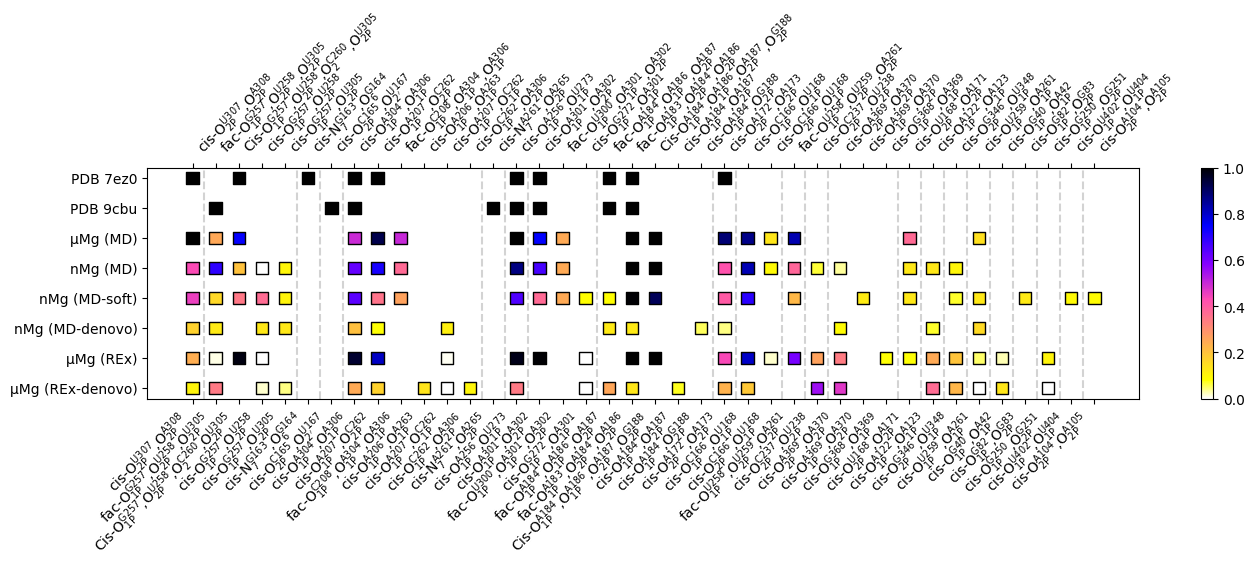

In [8]:
n_motifs = 40
n_sims = len(p.columns)

fig, ax = plt.subplots(figsize=(16, 3))

ax.invert_yaxis()

p_ = p.iloc[:n_motifs]

group = p_.index[0][0]
for i, (ndx, row) in enumerate(p_.iterrows()):
    ax.scatter(np.ones(n_sims) * i, np.arange(n_sims), c=row, cmap='gnuplot2_r', edgecolors='k', s=80, marker='s', vmin=0, vmax=1)
    if ndx[0] != group:
        group = ndx[0]
        ax.axvline(i-0.5, ls='dashed', color='lightgray')

ax.tick_params(top=True, labeltop=True, bottom=True, labelbottom=True)
ax.set_yticks(range(n_sims), p.columns)
ax.set_xticks(range(len(p_)), motif_latex.loc[p_.index.get_level_values('motif')], rotation=45)

for t in ax.get_xticklabels()[:n_motifs]:
    t.set_ha('right')
for t in ax.get_xticklabels()[n_motifs:]:
    t.set_ha('left')


from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
plt.colorbar(ScalarMappable(norm=Normalize(0, 1), cmap='gnuplot2_r'), ax=ax)

In [10]:
# Collect all motifs summaries

res = pd.DataFrame()

# Replex
systems = ['7ez0', '7ez0_noion']
for sys in systems:
    _res = pd.read_parquet(PROJECT_DIR / f'replex/{sys}/mMg_tip3p/MG_motifs_summary_lambda0.parquet').assign(sim=f'replex_{sys}_mMg_tip3p')
    res = pd.concat([res, _res])

# PlainMD
systems = ['7ez0', '7ez0_noion']
forcefields = ['mMg_tip3p', 'nMg_tip3p', 'nMg_tip3p_soft']
for sys, ff in itertools.product(systems, forcefields):
    try:
        _res = pd.read_parquet(PROJECT_DIR / f'plain_md/{sys}/{ff}/MG_motifs_summary.parquet').assign(sim=f'plain_md_{sys}_{ff}')
    except FileNotFoundError:
        pass
    else:
        res = pd.concat([res, _res])

# References
_res = pd.read_parquet(PROJECT_DIR / f'structures/7ez0/mMg_tip3p/MG_motifs_summary.parquet').assign(sim=f'7ez0')
res = pd.concat([res, _res])
_res = pd.read_parquet(PROJECT_DIR / f'structures/9cbu/MG_motifs_summary.parquet').assign(sim=f'9cbu')
res = pd.concat([res, _res])
res = res.drop(index="").reset_index()
res = res.query('n_inner == 1')

In [12]:
res[['inner_indices', 'inner_names', 'inner_resids', 'inner_resnames']] = res[['inner_indices', 'inner_names', 'inner_resids', 'inner_resnames']].map(lambda x: x[0])

In [27]:
res.query('inner_names == "O1P" or inner_names == "O2P"').set_index(['inner_resids', 'motif', 'sim'])['p'].unstack('sim').rename(columns=sim_labels).style.background_gradient(axis=None).format(precision=2)

<Axes: xlabel='inner_resids', ylabel='p'>

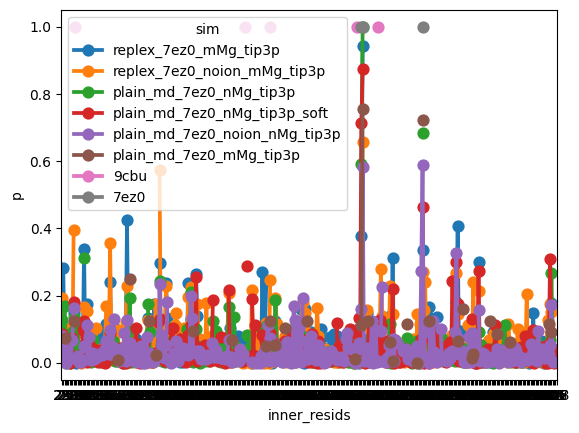

In [16]:
sns.pointplot(
    res.query('inner_names == "O1P"'),
    x='inner_resids',
    y='p',
    hue='sim',
)

In [ ]:
fig, ax = plt.subplots(figsize=(12, 4))

ax.scatter(
    np.arange(len(motifs)).repeat(len(sims)),
    np.tile(np.arange(len(sims)), len(motifs)),
    c=out,
    marker='s',
    edgecolors='black',
    s=100,
    cmap='magma_r',
)
ax.invert_yaxis()
ax.set_aspect(1)
ax.set_yticks(np.arange(len(sims)), labels=sims)
ax.set_xticks(np.arange(len(motifs)), labels=motifs, rotation=45, ha='left')
ax.tick_params(top=True, labeltop=True, bottom=False, labelbottom=False)

In [ ]:
out.max()

In [ ]:
sns.barplot(
    x,
    x='n_inner',
    y='%',
    errorbar=_agg,
    capsize=0.1,
)

In [ ]:
def _plot(data, **kws):
    x = data.groupby(['frame', 'n_inner]').size()
    res = bayesian_bootstrap(x, np.average)

In [ ]:
# Replex
systems = ['7ez0']
forcefields = ['mMg_tip3p']
replicates = [0]
repids = [0, 7]
ions = ['MG']

df = pd.DataFrame()
for system, forcefield, replicate, repid, ion in itertools.product(systems, forcefields, replicates, repids, ions):
    path = PROJECT_DIR / 'replex' / system / forcefield / f'replicate{replicate}' / f'rep{repid:02d}'
    _df = pd.read_csv(path / f'{ion}_OW_motifs.csv', na_filter=False, usecols=['time', 'index', 'n_inner', 'mgrna'])
    _df['system'] = system
    _df['forcefield'] = forcefield
    _df['repid'] = int(repid)
    _df['replicate'] = replicate
    _df['method'] = 'replex'
    df = pd.concat([df, _df])

# PlainMD
systems = ['7ez0']
forcefields = ['mMg_tip3p', 'nMg_tip3p']
replicates = range(8)
ions = ['MG']

for system, forcefield, replicate, repid, ion in itertools.product(systems, forcefields, replicates, repids, ions):
    try:
        path = PROJECT_DIR / 'plain_md' / system / forcefield / f'rep{replicate:02d}'
        _df = pd.read_csv(path / f'{ion}_OW_motifs.csv', na_filter=False, usecols=['time', 'index', 'n_inner', 'mgrna'])
        _df['system'] = system
        _df['forcefield'] = forcefield
        _df['replicate'] = replicate
        _df['method'] = 'plain_md'
        df = pd.concat([df, _df])
    except FileNotFoundError as e:
        print(e)
        pass

for col in ['mgrna', 'forcefield', 'system', 'method']:
    df[col] = df[col].astype('category')

In [ ]:
df['repid'] = df['repid'].fillna(0).astype(int)
df['sim'] = df['method'].str.cat(df['forcefield'], sep='_').str.cat(df['repid'].astype(str), sep='_')
df['sim'] = df['sim'].map({
    'replex_mMg_tip3p_0': 'μMg (REx, $λ_0$)',
    'replex_mMg_tip3p_7': 'μMg (REx, $λ_7$)',
    'plain_md_mMg_tip3p_0': 'μMg (MD)',
    'plain_md_nMg_tip3p_0': 'nMg (MD)',
})

In [ ]:
df.head()

In [ ]:
palette = ['tomato', 'darkred', 'gray', 'mediumpurple']
labels = ['μMg (REx, $λ_0$)', 'μMg (REx, $λ_7$)', 'μMg (MD)', 'nMg (MD)']

tstart_replex = 50000  # ps
tstart_plain_md = 150000
grouped = df.query(f"(method == 'replex' and time >= {tstart_replex}) or (method == 'plain_md' and time >= {tstart_plain_md})")

sns.set_style("ticks", {'axes.grid': True})



In [ ]:
palette = ['tomato', 'darkred', 'gray', 'mediumpurple']
labels = ['μMg (REx, $λ_0$)', 'μMg (REx, $λ_7$)', 'μMg (MD)', 'nMg (MD)']

tstart_replex = 50000  # ps
tstart_plain_md = 150000
grouped = df.query(f"(method == 'replex' and time >= {tstart_replex}) or (method == 'plain_md' and time >= {tstart_plain_md})")

sns.set_style("ticks", {'axes.grid': True})

ax = sns.histplot(grouped,
    y='n_inner',
    hue='sim',
    hue_order=labels,
    palette=palette,
    stat='percent',
    discrete=True,
    multiple='dodge',
    common_norm=False,
)

# ax.add_legend(g._legend_data, loc='center', bbox_to_anchor=(0.5, 1), ncol=len(labels))
ax.set_xscale('log')
ax.set_xlabel("[%]")
ax.set_ylabel(r"Coordination")
plt.gcf().set_size_inches((5, 5))
plt.tight_layout()
plt.savefig('figures/average_n_inner.pdf', bbox_inches='tight')

### Inner-bound (< 2.8 Å)

In [ ]:
# Replex
systems = ['7ez0', '7ez0_noion']
forcefields = ['mMg_tip3p']
replicates = [0]
repids = [0]
ions = ['MG', 'NA']

df = []
for system, forcefield, replicate, repid, ion in itertools.product(systems, forcefields, replicates, repids, ions):
    path = PROJECT_DIR / 'replex' / system / forcefield / f'replicate{replicate}' / f'rep{repid:02d}'
    _df = pd.read_csv(path / f'{ion}_motifs.csv', na_filter=False)
    _df = _df.loc[_df['time'] % 1000.0 == 0]
    _df['system'] = system
    _df['forcefield'] = forcefield
    _df['repid'] = repid
    _df['replicate'] = replicate
    _df['method'] = 'replex'
    df.append(_df)

# PlainMD
systems = ['7ez0', '7ez0_noion']
forcefields = ['nMg_tip3p_hard', 'mMg_tip3p_hard', 'nMg_tip3p']
replicates = range(8)
ions = ['MG', 'NA']

for system, forcefield, replicate, repid, ion in itertools.product(systems, forcefields, replicates, repids, ions):
    try:
        path = PROJECT_DIR / 'plain_md' / system / forcefield / f'rep{replicate:02d}'
        _df = pd.read_csv(path / f'{ion}_motifs.csv', na_filter=False)
        _df = _df.loc[_df['time'] % 1000.0 == 0]
        _df['system'] = system
        _df['forcefield'] = forcefield
        _df['replicate'] = replicate
        _df['method'] = 'plain_md'
        df.append(_df)
    except FileNotFoundError as e:
        print(e)
        pass

df = pd.concat(df)
for col in ['name', 'mgrna', 'forcefield', 'system', 'method']:
    df[col] = df[col].astype('category')


In [ ]:
tstart_replex = 50000  # ps
tstart_plain_md = 150000

grouped = df.query(f"(method == 'replex' and time >= {tstart_replex}) or (method == 'plain_md' and time >= {tstart_plain_md})").groupby(
    ['time', 'name', 'n_inner', 'forcefield', 'system', 'replicate', 'method'], observed=True
    ).size().reset_index(name='counts')

In [ ]:
# Compute unbound by taking the complement
n_tot = {'MG': 178, 'NA': 121}
tot = grouped.groupby(['time', 'name', 'forcefield', 'system', 'replicate', 'method'], observed=True).sum()['counts'].reset_index()
tot['tot'] = tot['name'].map(n_tot).astype(int)
tot['counts'] = tot['tot'] - tot['counts']
tot = tot.drop(columns='tot')
tot.insert(2, 'n_inner', -1)
grouped = pd.concat([grouped, tot])
grouped['sim'] = grouped['method'].str.cat(grouped['forcefield'], sep='_')
grouped['sim'] = grouped['sim'].map({
    'replex_mMg_tip3p': 'μMg (REx)',
    'plain_md_mMg_tip3p_hard': 'μMg (MD)',
    'plain_md_nMg_tip3p_hard': 'nMg (MD)',
    'plain_md_nMg_tip3p': 'nMg (MD-soft)',
})
grouped['binding'] = grouped['n_inner'].replace(-1, 'Bulk').replace(0, 'Outer')
grouped = grouped.sort_values('n_inner')

In [ ]:
grouped.query("forcefield == 'nMg_tip3p'")

In [ ]:
palette = ['tomato', 'gray', 'mediumpurple', 'mediumpurple']
labels = ['μMg (REx)', 'μMg (MD)', 'nMg (MD)', 'nMg (MD-soft)']

g = sns.FacetGrid(grouped, row='name', col='system', sharey='row')
sns.set_style("ticks", {'axes.grid': True})

g.map_dataframe(
    sns.barplot,
    y='binding',
    x='counts',
    orient='h',
    hue='sim',
    hue_order=labels,
    palette=palette,
)

g.add_legend(g._legend_data, loc='center', bbox_to_anchor=(0.5, 1), ncol=len(labels))
g.set_xlabels("Avg. number")
g.set_ylabels(r"Coordination")
g.set_titles("{row_name} ({col_name})")
plt.gcf().set_size_inches((5, 5))
plt.tight_layout()
plt.savefig('figures/average_coordination.pdf', bbox_inches='tight')

## Inner-bound sites

In [ ]:
tstart_replex = 50000  # ps
tstart_plain_md = 150000

grouped = df.query(f"((method == 'replex' and time >= {tstart_replex}) or (method == 'plain_md' and time >= {tstart_plain_md})) and n_inner > 0").copy()
grouped['inner_names'] = grouped['inner_names'].map(literal_eval)

In [ ]:
grouped = grouped.explode('inner_names')

In [ ]:
# Count by name
grouped = grouped.groupby(['name', 'system', 'method', 'forcefield', 'inner_names'], observed=True).size()


In [ ]:
grouped.groupby(['name', 'system', 'method', 'forcefield'], observed=True).sum()

In [ ]:
grouped = (grouped / grouped.groupby(['name', 'system', 'method', 'forcefield'], observed=True).sum())

In [ ]:
grouped = grouped.reset_index(name='proportion')

In [ ]:
grouped

In [ ]:
grouped['sim'] = grouped['method'].str.cat(grouped['forcefield'], sep='_')
grouped['sim'] = grouped['sim'].map({
    'replex_mMg_tip3p': 'μMg (REx)',
    'plain_md_mMg_tip3p_hard': 'μMg (MD)',
    'plain_md_nMg_tip3p_hard': 'nMg (MD)',
})
palette = ['tomato', 'gray', 'mediumpurple']
labels = ['μMg (REx)', 'μMg (MD)', 'nMg (MD)']

g = sns.FacetGrid(grouped, row='name', col='system', sharey='row')
sns.set_style("ticks", {'axes.grid': True})

g.map_dataframe(
    sns.barplot,
    y='inner_names',
    x='proportion',
    orient='h',
    hue='sim',
    hue_order=labels,
    palette=palette,
    order=grouped[grouped['proportion'] > 0.01].sort_values('proportion', ascending=False)['inner_names'].unique(),
)

g.add_legend(g._legend_data, loc='center', bbox_to_anchor=(0.5, 1), ncol=len(labels))
g.set_xlabels("Proportion")
g.set_ylabels("Inner-bound atom type")
g.set_titles("{row_name} ({col_name})")
for axis in g.axes.flat:
    axis.tick_params(labelleft=True)
plt.gcf().set_size_inches((5, 5))
plt.tight_layout()
plt.savefig('figures/binding_sites.pdf', bbox_inches='tight')

### Summarize motifs